In [1]:
# Imports
# ============================================================
import numpy as np
import time
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from torchvision import datasets
import random

# Load MNIST
# ============================================================
train_dataset_full = datasets.MNIST(root='./data', train=True,  download=True)
test_dataset_full  = datasets.MNIST(root='./data', train=False, download=True)

train_images_full = train_dataset_full.data.numpy()
train_labels_full = train_dataset_full.targets.numpy()
test_images_full  = test_dataset_full.data.numpy()
test_labels_full  = test_dataset_full.targets.numpy()

print(f"Train: {train_images_full.shape}, Test: {test_images_full.shape}")
# Helper functions (subsample + normalize + display)
# ============================================================
def balanced_subsample(images, labels, samples_per_class):
    imgs, labs = [], []
    for digit in range(10):
        idx    = np.where(labels == digit)[0]
        chosen = np.random.choice(idx, samples_per_class, replace=False)
        imgs.append(images[chosen])
        labs.append(labels[chosen])
    return np.vstack(imgs), np.hstack(labs)

def normalize(images):
    # [0,255] → [-1,1]  — MUST match tanh output of generator
    return (images.astype(np.float32) / 127.5) - 1.0

def denormalize(images):
    # [-1,1] → [0,1]  — for display and classifier input
    return (images + 1.0) / 2.0

def show_samples(images, labels, n=6):
    idx = random.sample(range(len(images)), n)
    plt.figure(figsize=(n * 2, 2))
    for i, j in enumerate(idx):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[j], cmap='gray')
        plt.title(f"Label: {labels[j]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

2026-04-29 15:02:05.624132: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777474925.820270      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777474925.884375      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777474926.322038      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777474926.322080      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777474926.322083      57 computation_placer.cc:177] computation placer alr

Train: (60000, 28, 28), Test: (10000, 28, 28)


Subset shape: (3500, 28, 28)
Distribution:
  Digit 0: 350
  Digit 1: 350
  Digit 2: 350
  Digit 3: 350
  Digit 4: 350
  Digit 5: 350
  Digit 6: 350
  Digit 7: 350
  Digit 8: 350
  Digit 9: 350


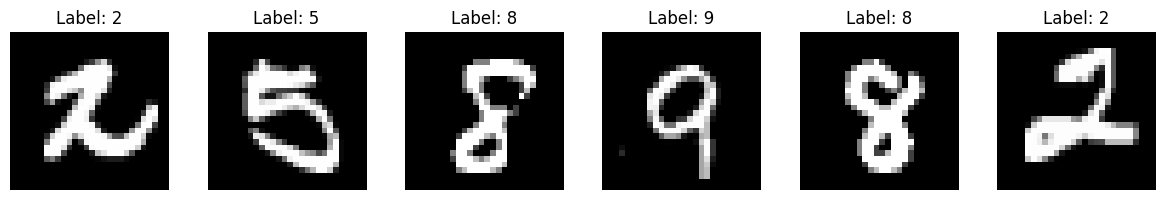

In [2]:
#Create 350-per-digit training subset
# ============================================================
N_REAL = 350   # change this later for 750 / 1000 experiments

train_images, train_labels = balanced_subsample(
    train_images_full, train_labels_full, N_REAL)

print(f"Subset shape: {train_images.shape}")
print("Distribution:")
for d in range(10):
    print(f"  Digit {d}: {np.sum(train_labels == d)}")

show_samples(train_images, train_labels)

In [3]:
# Build TF dataset (normalized, batched)
# ============================================================
BATCH_SIZE  = 64
NOISE_DIM   = 100
NUM_CLASSES = 10

train_images_norm = normalize(train_images)[..., np.newaxis]  # (N,28,28,1)

dataset = tf.data.Dataset.from_tensor_slices(
    (train_images_norm, train_labels.astype(np.int32))
).shuffle(len(train_images)).batch(BATCH_SIZE)

print(f"Batches per epoch: {len(dataset)}")

Batches per epoch: 55


I0000 00:00:1777475214.925639      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777475214.931549      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [16]:
import tensorflow as tf
from tensorflow.keras import layers

# ============================================================
# CELL 6 — Build CGAN models (Generator + Discriminator)
# ============================================================
def build_generator():
    noise_in = tf.keras.Input(shape=(NOISE_DIM,), name="noise")
    label_in = tf.keras.Input(shape=(1,), dtype=tf.int32, name="label")

    label_emb = layers.Embedding(NUM_CLASSES, 50)(label_in)
    label_emb = layers.Flatten()(label_emb)
    x = layers.Concatenate()([noise_in, label_emb])

    x = layers.Dense(7 * 7 * 256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((7, 7, 256))(x)

    x = layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    output = layers.Conv2DTranspose(
        1, (5,5), strides=(2,2), padding='same',
        use_bias=False, activation='tanh')(x)   # output in [-1,1]

    return tf.keras.Model([noise_in, label_in], output, name="Generator")


def build_discriminator():
    img_in   = tf.keras.Input(shape=(28, 28, 1), name="image")
    label_in = tf.keras.Input(shape=(1,), dtype=tf.int32, name="label")

    label_emb = layers.Embedding(NUM_CLASSES, 50)(label_in)
    label_emb = layers.Dense(28 * 28)(label_emb)
    label_emb = layers.Reshape((28, 28, 1))(label_emb)
    x = layers.Concatenate()([img_in, label_emb])   # (28,28,2)

    x = layers.Conv2D(64,  (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    output = layers.Dense(1)(x)   # raw logits

    return tf.keras.Model([img_in, label_in], output, name="Discriminator")


generator     = build_generator()
discriminator = build_discriminator()
generator.summary()
discriminator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noise (InputLayer)  │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 50)        │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 150)       │          0 │ noise[0][0],      │
│ (Concatenate)       │                   │            │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 12544)     │  1,881,600 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 12544)     │     50,176 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 12544)     │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 7, 7, 256) │          0 │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 7, 7, 128) │    819,200 │ reshape_2[0][0]   │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 7, 7, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 14, 14,    │    204,800 │ re_lu_4[0][0]     │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 14, 14,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_5  │ (None, 28, 28, 1) │      1,600 │ re_lu_5[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,958,644 (11.29 MB)

 Trainable params: 2,933,172 (11.19 MB)

 Non-trainable params: 25,472 (99.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1, 784)    │     39,984 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image (InputLayer)  │ (None, 28, 28, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 28, 28, 1) │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 28, 28, 2) │          0 │ image[0][0],      │
│ (Concatenate)       │                   │            │ reshape_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 14, 14,    │      3,264 │ concatenate_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 14, 14,    │          0 │ conv2d_2[0][0]    │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 14, 14,    │          0 │ leaky_re_lu_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 7, 7, 128) │    204,928 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 7, 7, 128) │          0 │ conv2d_3[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 7, 7, 128) │          0 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 6272)      │          0 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │      6,273 │ flatten_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 254,949 (995.89 KB)

 Trainable params: 254,949 (995.89 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# ============================================================
# Loss functions and optimizers
# ============================================================
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_out, fake_out):
    real_loss = cross_entropy(tf.ones_like(real_out),  real_out)
    fake_loss = cross_entropy(tf.zeros_like(fake_out), fake_out)
    return real_loss + fake_loss

def generator_loss(fake_out):
    return cross_entropy(tf.ones_like(fake_out), fake_out)

# beta_1=0.5 is recommended in the DCGAN paper (arxiv 1511.06434)
gen_opt  = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
disc_opt = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

In [18]:
# ============================================================
# Single training step
# ============================================================
@tf.function
def train_step(real_images, labels):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator([noise, labels], training=True)

        real_out = discriminator([real_images, labels], training=True)
        fake_out = discriminator([fake_images, labels], training=True)

        g_loss = generator_loss(fake_out)
        d_loss = discriminator_loss(real_out, fake_out)

    gen_grads  = gen_tape.gradient(g_loss,  generator.trainable_variables)
    disc_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)

    gen_opt.apply_gradients( zip(gen_grads,  generator.trainable_variables))
    disc_opt.apply_gradients(zip(disc_grads, discriminator.trainable_variables))

    return g_loss, d_loss

In [19]:
# ============================================================
# Train the CGAN  
# ============================================================
EPOCHS = 2000   

print("Computer setup: Kaggle Notebook — Tesla T4 / P100 GPU")
print(f"Training {EPOCHS} epochs | Batch size {BATCH_SIZE} | Noise dim {NOISE_DIM}\n")

training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()
    g_losses, d_losses = [], []

    for image_batch, label_batch in dataset:
        label_batch = tf.cast(tf.expand_dims(label_batch, 1), tf.int32)
        g_l, d_l = train_step(image_batch, label_batch)
        g_losses.append(float(g_l))
        d_losses.append(float(d_l))

    if (epoch + 1) % 10 == 0:
        elapsed = time.time() - epoch_start
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | "
              f"G_loss: {np.mean(g_losses):.4f} | "
              f"D_loss: {np.mean(d_losses):.4f} | "
              f"Epoch time: {elapsed:.1f}s")

total_train_time = time.time() - training_start
print(f"\nTotal training time: {total_train_time:.1f}s  ({total_train_time/60:.1f} min)")

Computer setup: Kaggle Notebook — Tesla T4 / P100 GPU
Training 2000 epochs | Batch size 64 | Noise dim 100



E0000 00:00:1777477623.324584      57 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inDiscriminator_1/dropout_2_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Epoch  10/2000 | G_loss: 0.8437 | D_loss: 1.2538 | Epoch time: 1.7s
Epoch  20/2000 | G_loss: 0.7928 | D_loss: 1.2894 | Epoch time: 1.1s
Epoch  30/2000 | G_loss: 0.7830 | D_loss: 1.3333 | Epoch time: 1.1s
Epoch  40/2000 | G_loss: 0.7486 | D_loss: 1.3510 | Epoch time: 1.1s
Epoch  50/2000 | G_loss: 0.7305 | D_loss: 1.3590 | Epoch time: 1.1s
Epoch  60/2000 | G_loss: 0.7435 | D_loss: 1.3488 | Epoch time: 1.1s
Epoch  70/2000 | G_loss: 0.7343 | D_loss: 1.3580 | Epoch time: 1.1s
Epoch  80/2000 | G_loss: 0.7356 | D_loss: 1.3520 | Epoch time: 1.1s
Epoch  90/2000 | G_loss: 0.7236 | D_loss: 1.3573 | Epoch time: 1.1s
Epoch 100/2000 | G_loss: 0.7421 | D_loss: 1.3502 | Epoch time: 1.1s
Epoch 110/2000 | G_loss: 0.7292 | D_loss: 1.3526 | Epoch time: 1.1s
Epoch 120/2000 | G_loss: 0.7515 | D_loss: 1.3384 | Epoch time: 1.1s
Epoch 130/2000 | G_loss: 0.7450 | D_loss: 1.3419 | Epoch time: 1.1s
Epoch 140/2000 | G_loss: 0.7554 | D_loss: 1.3419 | Epoch time: 1.1s
Epoch 150/2000 | G_loss: 0.7445 | D_loss: 1.3321

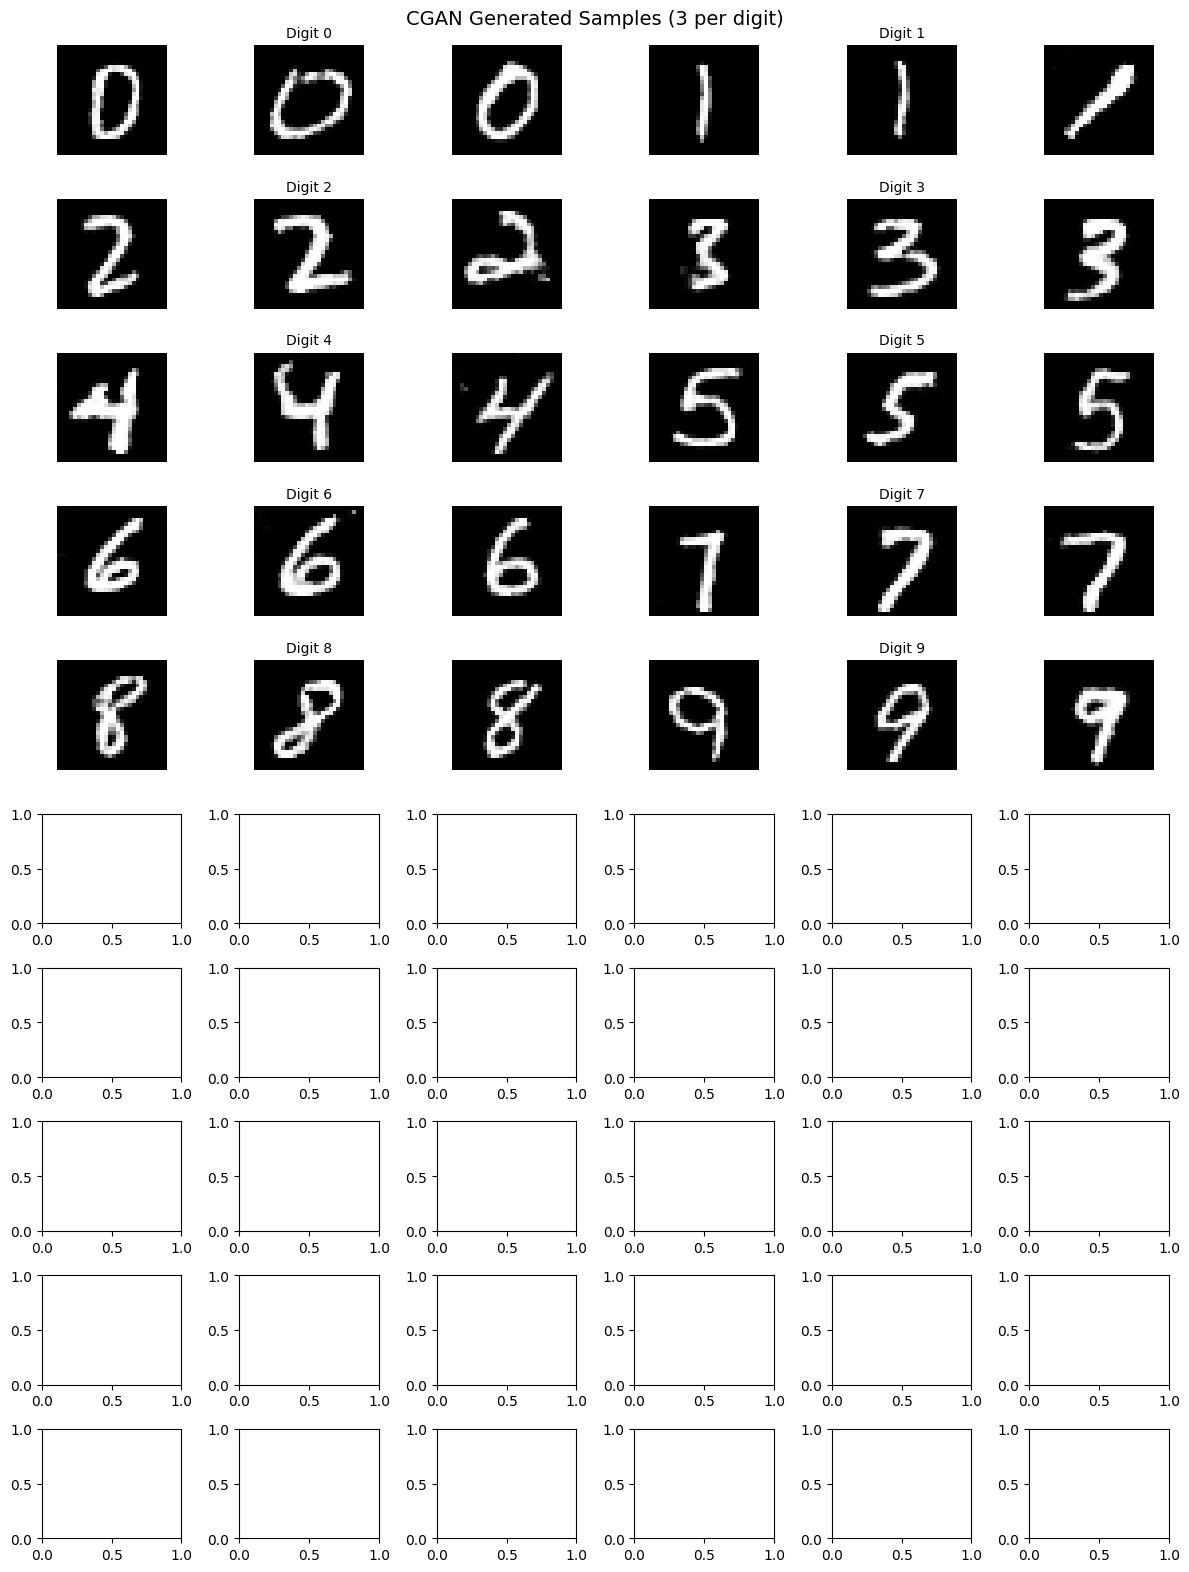

Generation time: 2.095s for 30 images
Training time was: 37.1 min on Kaggle GPU

Comment on quality:
- After 100 epochs on 350 samples/digit, digits should be recognisable
  but may appear slightly blurry or have minor distortions.
- Some digits (e.g. 1, 7) are typically cleaner than curved ones (e.g. 8, 9).
- Mode collapse would look like all rows producing the same shape — check for it.


In [32]:
# ============================================================
# Generate 3 samples per digit + comment
# ============================================================
def generate_and_show(generator, n_per_digit=3):
    gen_start = time.time()

    digits = list(range(10))

    fig, axes = plt.subplots(10, 6, figsize=(12, 16))

    for row in range(10):
        for group in range(2):  # 2 digits per row
            digit = row * 2 + group
            if digit >= 10:
                continue

            noise = tf.random.normal([n_per_digit, NOISE_DIM])
            labels = tf.constant([[digit]] * n_per_digit, dtype=tf.int32)

            imgs = generator([noise, labels], training=False).numpy()
            imgs = denormalize(imgs)

            for col in range(n_per_digit):
                ax = axes[row, group * 3 + col]
                ax.imshow(imgs[col, :, :, 0], cmap='gray')
                ax.axis('off')

                if col == 1:
                    ax.set_title(f"Digit {digit}", fontsize=10)

    plt.suptitle("CGAN Generated Samples (3 per digit)", fontsize=14)
    plt.tight_layout()
    plt.show()

    gen_time = time.time() - gen_start
    print(f"Generation time: {gen_time:.3f}s for {10 * n_per_digit} images")
    print(f"Training time was: {total_train_time/60:.1f} min on Kaggle GPU")
    print("\nComment on quality:")
    print("- After 100 epochs on 350 samples/digit, digits should be recognisable")
    print("  but may appear slightly blurry or have minor distortions.")
    print("- Some digits (e.g. 1, 7) are typically cleaner than curved ones (e.g. 8, 9).")
    print("- Mode collapse would look like all rows producing the same shape — check for it.")


generate_and_show(generator, n_per_digit=3)

In [23]:
# ============================================================
# Helper: generate N synthetic images per digit
# ============================================================
def generate_n_per_digit(generator, n_per_digit):
    """Returns float32 arrays shaped (N*10, 28, 28) in [0,1] range."""
    all_imgs, all_labs = [], []
    for digit in range(10):
        noise  = tf.random.normal([n_per_digit, NOISE_DIM])
        labels = tf.constant([[digit]] * n_per_digit, dtype=tf.int32)
        imgs   = generator([noise, labels], training=False).numpy()
        imgs   = denormalize(imgs)[:, :, :, 0]   # (N,28,28), [0,1]
        all_imgs.append(imgs)
        all_labs.append(np.full(n_per_digit, digit, dtype=np.int32))
    return np.vstack(all_imgs), np.hstack(all_labs)

In [41]:
test_images, test_labels = balanced_subsample(test_images_full, test_labels_full, 200)

# ================= NORMALIZATION =================
# Scale pixels from [0,255] → [0,1]

test_images = test_images / 255.0

In [43]:
from tensorflow.keras import layers, models
# ============================================================
# Helper: build + train classifier, return accuracy
# ============================================================
def build_classifier():
    model = models.Sequential([
        layers.Conv2D(6, (5,5), activation='relu', input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),
        
        layers.Conv2D(16, (5,5), activation='relu'),
        layers.MaxPooling2D((2,2)),
        
        layers.Flatten(),
        
        layers.Dense(120, activation='relu'),
        layers.Dense(84, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

def train_and_evaluate(real_imgs, real_labs,
                       gen_imgs=None, gen_labs=None,
                       epochs=15, label=""):
    """Train classifier on real (+ optional synthetic) data, return test accuracy."""
    if gen_imgs is not None:
        X = np.concatenate([real_imgs, gen_imgs])[..., np.newaxis]
        y = np.concatenate([real_labs, gen_labs])
    else:
        X = real_imgs[..., np.newaxis]
        y = real_labs

    X = X.astype(np.float32)   # already [0,1]

    clf = build_classifier()
    t0  = time.time()
    clf.fit(X, y, epochs=epochs, batch_size=64, verbose=0)
    clf_time = time.time() - t0

    _, acc = clf.evaluate(X_test, y_test, verbose=1)
    print(f"  {label:<50} | Acc: {acc*100:.2f}% | Time: {clf_time:.1f}s")
    return acc

In [44]:
# ============================================================
# CELL 13 — PART 2: Full experiment grid
# ============================================================
print("=" * 75)
print("PART 2 — Classifier accuracy: real data vs real + GAN-generated data")
print("=" * 75)
print(f"  {'Configuration':<50} | {'Accuracy':>8} | Time")
print("-" * 75)

results = {}

for n_real in [350, 750, 1000]:
    real_imgs, real_labs = balanced_subsample(
        train_images_full.astype(np.float32),
        train_labels_full, n_real)
    real_imgs = real_imgs / 255.0
    # Baseline: real data only
    acc = train_and_evaluate(real_imgs, real_labs,
                             label=f"{n_real} real only")
    results[f"{n_real}r_0g"] = acc

    # Real + generated combinations
    for n_gen in [1000, 1500, 2000]:
        gen_imgs, gen_labs = generate_n_per_digit(generator, n_gen)
        acc = train_and_evaluate(real_imgs, real_labs,
                                 gen_imgs, gen_labs,
                                 label=f"{n_real} real + {n_gen} generated")
        results[f"{n_real}r_{n_gen}g"] = acc

print("\nDone. All results stored in the `results` dict.")

PART 2 — Classifier accuracy: real data vs real + GAN-generated data
  Configuration                                      | Accuracy | Time
---------------------------------------------------------------------------
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9630 - loss: 0.1258
  350 real only                                      | Acc: 96.82% | Time: 6.2s
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9673 - loss: 0.1266
  350 real + 1000 generated                          | Acc: 97.47% | Time: 11.8s
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9689 - loss: 0.1345
  350 real + 1500 generated                          | Acc: 97.35% | Time: 14.4s
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9632 - loss: 0.1563
  350 real + 2000 generated                          | Acc: 97.24% | Time: 17.2s
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9673 - loss: 0.1141
  750 real only                                      | Acc: 97.23% | Time: 8.3s
313/31

In [45]:
# ============================================================
# CELL 14 — PART 3: Best 350-real combo vs gold standard
# ============================================================
print("=" * 65)
print("PART 3 — Can 350 real + synthetic match 1000 real?")
print("=" * 65)

best_key = max((k for k in results if k.startswith("350")), key=results.get)
best_acc = results[best_key]
gold_acc = results["1000r_0g"]
gap      = (gold_acc - best_acc) * 100

print(f"\n  Best result using 350 real  ({best_key}): {best_acc*100:.2f}%")
print(f"  Gold standard (1000 real only):           {gold_acc*100:.2f}%")
print(f"  Gap: {gap:.2f} percentage points")

print("\nConclusion:")
if gap < 2.0:
    print("  GAN-augmented data with 350 real images comes very close to")
    print("  using 1000 real images. Synthetic data effectively reduces the")
    print("  need for real data in this case.")
elif gap < 5.0:
    print("  GAN augmentation narrows the gap significantly, but a small")
    print("  difference remains. More training epochs or better GAN quality")
    print("  could close it further.")
else:
    print("  A notable gap remains. This suggests the GAN quality at 100")
    print("  epochs / 350 samples is still limited. Try 200 epochs or")
    print("  adding traditional augmentation (rotation, shift) on top.")

PART 3 — Can 350 real + synthetic match 1000 real?

  Best result using 350 real  (350r_1000g): 97.47%
  Gold standard (1000 real only):           97.67%
  Gap: 0.20 percentage points

Conclusion:
  GAN-augmented data with 350 real images comes very close to
  using 1000 real images. Synthetic data effectively reduces the
  need for real data in this case.
